# Seminar. Practical aspects of diffusion models
## Part 2 — A tiny DiT from scratch (≈25 min)

* DiT with **AdaLN-Zero** conditioning on time and class (lecture: *Architectures*)
* **Time distribution**: logit-normal + resolution shift (lecture: *Loss in practice*)
* Training on FashionMNIST: ~2–3 min live, longer-trained checkpoints are loaded afterwards
* **CFG vs interval CFG vs autoguidance**, measured with FID and a classifier "alignment score" (lecture: *Quality evaluation*, *Guidance*)

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


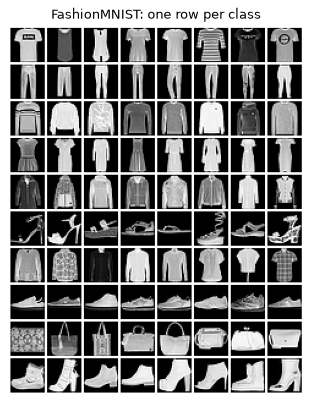

In [1]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # pick a free GPU (check nvidia-smi)

import math, time, copy
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

torch.set_num_threads(4)
dev = 'cuda'
torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 80})
os.makedirs('ckpts', exist_ok=True)

ds = torchvision.datasets.FashionMNIST('data', train=True, download=True)
ds_test = torchvision.datasets.FashionMNIST('data', train=False, download=True)
X = (ds.data.float() / 127.5 - 1).unsqueeze(1).to(dev)            # [60000, 1, 28, 28] in [-1, 1]
Y = ds.targets.to(dev)
X_test = (ds_test.data.float() / 127.5 - 1).unsqueeze(1).to(dev)
Y_test = ds_test.targets.to(dev)
CLASSES = ds.classes

def show(imgs, nrow, title=None, ax=None, scale=1.0):
    grid = torchvision.utils.make_grid(imgs.float().clamp(-1, 1).cpu(), nrow=nrow, normalize=True, value_range=(-1, 1), pad_value=1)
    if ax is None:
        plt.figure(figsize=(scale * nrow * 0.6, scale * (len(imgs) // nrow) * 0.6)); ax = plt.gca()
    ax.imshow(grid.permute(1, 2, 0)); ax.axis('off')
    if title: ax.set_title(title)

show(torch.cat([X[Y == c][:8] for c in range(10)]), nrow=8, title='FashionMNIST: one row per class')
print(CLASSES)

## 1. DiT with AdaLN-Zero

* **Patchify**: 28×28 image, patch 2 → 14×14 = 196 tokens.
* **Conditioning** $c = \mathrm{emb}(t) + \mathrm{emb}(y)$ enters every block through AdaLN:
  $\mathrm{AdaLN}(x, c) = \mathrm{scale}(c)\cdot\mathrm{LN}(x) + \mathrm{shift}(c)$, plus a **gate** on each residual branch.
* **Zero init** of the modulation and of the output layer: every block starts as the identity and the model starts by predicting 0.
* Class `10` is the null class $\varnothing$ for CFG.

In [2]:
def modulate(x, shift, scale):
    return x * (1 + scale[:, None]) + shift[:, None]

class DiTBlock(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, elementwise_affine=False, eps=1e-6)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim, elementwise_affine=False, eps=1e-6)
        self.mlp = nn.Sequential(nn.Linear(dim, 4 * dim), nn.GELU(approximate='tanh'), nn.Linear(4 * dim, dim))
        self.adaLN = nn.Sequential(nn.SiLU(), nn.Linear(dim, 6 * dim))
        nn.init.zeros_(self.adaLN[1].weight); nn.init.zeros_(self.adaLN[1].bias)     # AdaLN-Zero

    def forward(self, x, c):
        shift1, scale1, gate1, shift2, scale2, gate2 = self.adaLN(c).chunk(6, dim=-1)
        h = modulate(self.norm1(x), shift1, scale1)
        x = x + gate1[:, None] * self.attn(h, h, h, need_weights=False)[0]
        x = x + gate2[:, None] * self.mlp(modulate(self.norm2(x), shift2, scale2))
        return x

def timestep_embedding(t, dim=256):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    a = 1000 * t[:, None] * freqs[None]
    return torch.cat([a.cos(), a.sin()], dim=-1)

class DiT(nn.Module):
    def __init__(self, img=28, ch=1, patch=2, dim=256, depth=8, heads=4, n_classes=10):
        super().__init__()
        self.p, self.n, self.ch = patch, img // patch, ch
        self.patch_embed = nn.Linear(patch * patch * ch, dim)
        self.pos = nn.Parameter(torch.randn(1, self.n ** 2, dim) * 0.02)
        self.t_embed = nn.Sequential(nn.Linear(256, dim), nn.SiLU(), nn.Linear(dim, dim))
        self.y_embed = nn.Embedding(n_classes + 1, dim)                          # +1 = null class
        self.blocks = nn.ModuleList([DiTBlock(dim, heads) for _ in range(depth)])
        self.norm_out = nn.LayerNorm(dim, elementwise_affine=False, eps=1e-6)
        self.adaLN_out = nn.Sequential(nn.SiLU(), nn.Linear(dim, 2 * dim))
        self.out = nn.Linear(dim, patch * patch * ch)
        for m in [self.adaLN_out[1], self.out]:
            nn.init.zeros_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x, t, y):
        B, p, n, ch = x.shape[0], self.p, self.n, self.ch
        x = x.reshape(B, ch, n, p, n, p).permute(0, 2, 4, 3, 5, 1).reshape(B, n * n, p * p * ch)   # patchify
        x = self.patch_embed(x) + self.pos
        c = self.t_embed(timestep_embedding(t)) + self.y_embed(y)
        for blk in self.blocks:
            x = blk(x, c)
        shift, scale = self.adaLN_out(c).chunk(2, dim=-1)
        x = self.out(modulate(self.norm_out(x), shift, scale))
        return x.reshape(B, n, n, p, p, ch).permute(0, 5, 1, 3, 2, 4).reshape(B, ch, n * p, n * p)  # unpatchify

NULL = 10
print(f'{sum(p.numel() for p in DiT().parameters()) / 1e6:.1f}M parameters')

9.8M parameters


## 2. Time distribution and the resolution shift

**Logit-normal**: $t = \sigma(u),\ u\sim\mathcal N(0,1)$ — concentrates training on intermediate $t$.

**Shift**: $t' = s(\alpha, t) = \frac{\alpha t}{1+(\alpha-1)t}$. Why? The lecture's argument: averaging $n$ noisy pixels that share the same content reduces the noise by $\sqrt n$.
A high-resolution image has more pixels per object → at the same $t$ it is effectively **less noisy**. Let's check this directly.

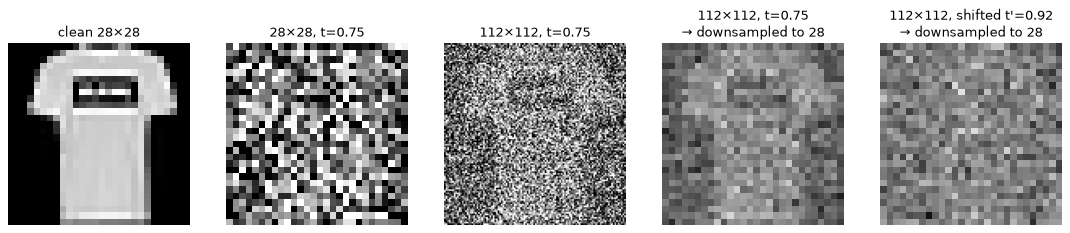

In [3]:
def shift_t(t, alpha):
    return alpha * t / (1 + (alpha - 1) * t)

img = X[1:2]
img_hr = F.interpolate(img, scale_factor=4, mode='bicubic')         # "the same image at 112x112"
t = 0.75
torch.manual_seed(1)
noisy_lr = (1 - t) * img + t * torch.randn_like(img)
noisy_hr = (1 - t) * img_hr + t * torch.randn_like(img_hr)
t_shift = shift_t(torch.tensor(t), 4.0).item()                      # α = sqrt(m/n) = sqrt(112²/28²) = 4
noisy_hr_shift = (1 - t_shift) * img_hr + t_shift * torch.randn_like(img_hr)

fig, axs = plt.subplots(1, 5, figsize=(17, 3.8))
for ax, im, title in zip(axs, [img, noisy_lr, noisy_hr, F.avg_pool2d(noisy_hr, 4), F.avg_pool2d(noisy_hr_shift, 4)],
                         ['clean 28×28', f'28×28, t={t}', f'112×112, t={t}', f'112×112, t={t}\n→ downsampled to 28', f"112×112, shifted t'={t_shift:.2f}\n→ downsampled to 28"]):
    show(im, 1, title, ax=ax)
plt.show()

Same $t$, but the 112×112 version (after averaging 4×4 pixels) is clearly less noisy. With the shifted $t' = s(4, t)$ the effective noise matches the 28×28 case.
This is why SD3 / FLUX / Z-Image shift both the training distribution and the sampling grid towards noise at high resolution.

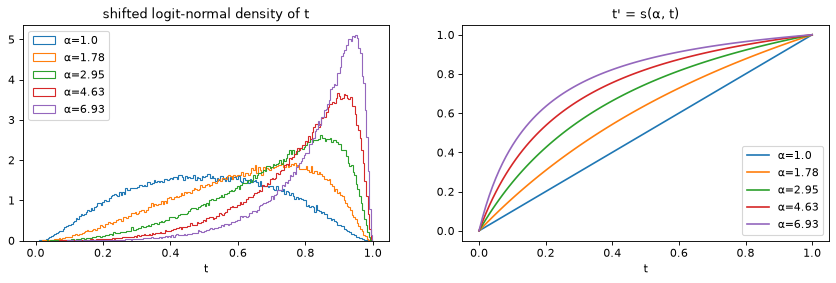

In [4]:
u = torch.randn(200_000)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.5))
for alpha in [1.0, 1.78, 2.95, 4.63, 6.93]:
    axs[0].hist(shift_t(torch.sigmoid(u), alpha).numpy(), bins=200, density=True, histtype='step', label=f'α={alpha}')
    tt = torch.linspace(0, 1, 100)
    axs[1].plot(tt, shift_t(tt, alpha), label=f'α={alpha}')
axs[0].set_title('shifted logit-normal density of t'); axs[0].legend(); axs[0].set_xlabel('t')
axs[1].set_title("t' = s(α, t)"); axs[1].set_xlabel('t'); axs[1].legend()
plt.show()

## 3. Training

The full recipe in ~15 lines: logit-normal $t$, label dropout (10%) for CFG, bf16 autocast, EMA of the weights.
28×28 is low resolution, so no shift ($\alpha=1$).

We train **live for 1500 steps** (~2–3 min on a shared H100) to see the dynamics.

In [5]:
def train(steps, batch=512, lr=3e-4, alpha=1.0, log_every=500, seed=0):
    torch.manual_seed(seed)
    net = DiT().to(dev)
    ema = copy.deepcopy(net).requires_grad_(False)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=0.0)
    t0 = time.time()
    for it in range(1, steps + 1):
        idx = torch.randint(0, len(X), (batch,), device=dev)
        x0, y = X[idx], Y[idx]
        y = torch.where(torch.rand(batch, device=dev) < 0.1, NULL, y)          # label dropout
        t = shift_t(torch.sigmoid(torch.randn(batch, device=dev)), alpha)     # shifted logit-normal
        eps = torch.randn_like(x0)
        tt = t[:, None, None, None]
        xt = (1 - tt) * x0 + tt * eps
        with torch.autocast('cuda', dtype=torch.bfloat16):
            v = net(xt, t, y)
        loss = F.mse_loss(v.float(), eps - x0)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        decay = min(0.9995, (1 + it) / (10 + it))                              # EMA with warm-up
        with torch.no_grad():
            torch._foreach_lerp_(list(ema.parameters()), list(net.parameters()), 1 - decay)
        if it % log_every == 0:
            print(f'step {it:5d}  loss {loss.item():.4f}  {time.time() - t0:.0f}s')
    return ema.eval()

net_small = train(1500)
torch.save(net_small.state_dict(), 'ckpts/dit_fmnist_1500steps.pt')

step   500  loss 0.2407  32s


step  1000  loss 0.2129  60s


step  1500  loss 0.1889  88s


## 4. Sampling with CFG

Euler on a uniform grid; CFG $v = v(x\mid\varnothing) + w\,(v(x\mid y) - v(x\mid\varnothing))$.
`bad_net` replaces $v(x\mid\varnothing)$ with a worse model's $v(x\mid y)$ — that is **autoguidance** (section 6).

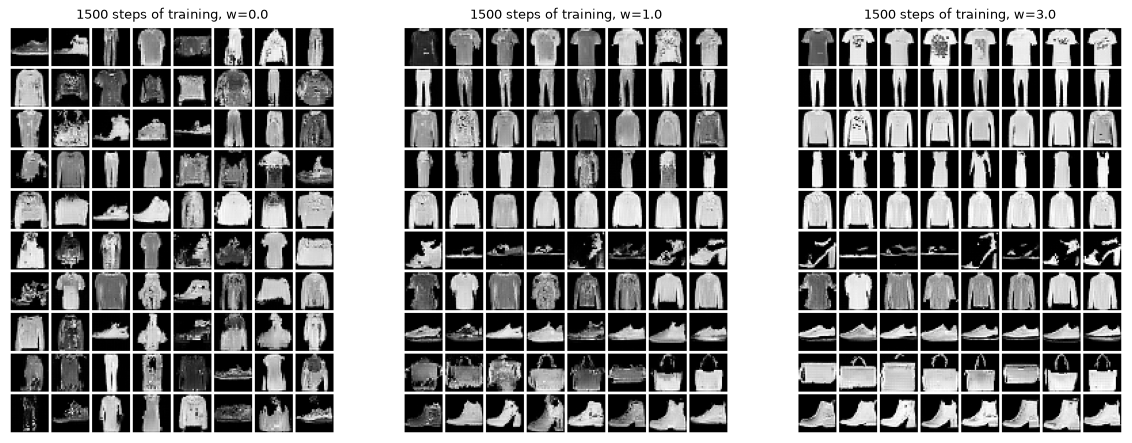

In [6]:
@torch.no_grad()
def sample(net, y, steps=32, w=1.0, interval=(0.0, 1.0), bad_net=None, seed=0, shift=1.0):
    g = torch.Generator(device=dev).manual_seed(seed)
    x = torch.randn(len(y), 1, 28, 28, device=dev, generator=g)
    ts = shift_t(torch.linspace(1, 0, steps + 1, device=dev), shift)
    y_null = torch.full_like(y, NULL)
    for i in range(steps):
        t = ts[i].expand(len(x))
        with torch.autocast('cuda', dtype=torch.bfloat16):
            v = net(x, t, y).float()
            if w != 1.0 and interval[0] <= ts[i] <= interval[1]:
                v_neg = bad_net(x, t, y).float() if bad_net is not None else net(x, t, y_null).float()
                v = v_neg + w * (v - v_neg)
        x = x + (ts[i + 1] - ts[i]) * v
    return x.clamp(-1, 1)

y_grid = torch.arange(10, device=dev).repeat_interleave(8)
fig, axs = plt.subplots(1, 3, figsize=(18, 7))
for ax, w in zip(axs, [0.0, 1.0, 3.0]):
    show(sample(net_small, y_grid, w=w), nrow=8, ax=ax, title=f'1500 steps of training, w={w}')
plt.show()

`w=0` is unconditional, `w=1` conditional, `w>1` guided. After 1.5k steps the unconditional samples are often broken; the class-conditional ones are already reasonable and guidance cleans them up further.

Now load models trained with the same code for longer (if a checkpoint is missing, it is trained here):
* `net` — 20k steps (~25 min), the main model;
* `net_bad` — 5k steps (4× shorter), the *bad model* for autoguidance.

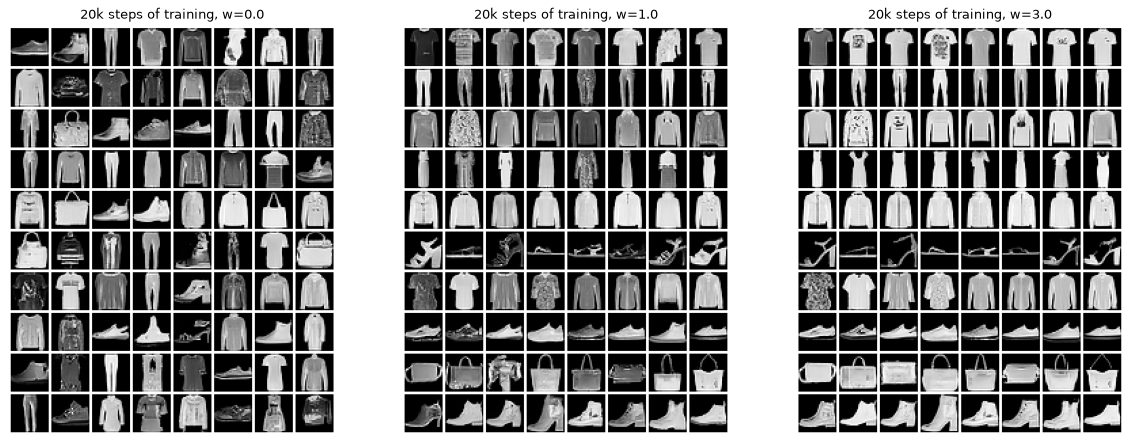

In [7]:
def load_or_train(steps, seed):
    path = f'ckpts/dit_fmnist_{steps // 1000}k.pt'
    if not os.path.exists(path):
        torch.save(train(steps, log_every=2000, seed=seed).state_dict(), path)
    m = DiT().to(dev).eval()
    m.load_state_dict(torch.load(path, map_location=dev))
    return m

net = load_or_train(20000, seed=0)
net_bad = load_or_train(5000, seed=1)

fig, axs = plt.subplots(1, 3, figsize=(18, 7))
for ax, w in zip(axs, [0.0, 1.0, 3.0]):
    show(sample(net, y_grid, w=w), nrow=8, ax=ax, title=f'20k steps of training, w={w}')
plt.show()

## 5. Quality evaluation: FID and an "alignment score"

FID compares feature statistics of generated and real images. For ImageNet-like data one uses Inception features; for FashionMNIST we train a small CNN classifier (~20 s) and use
* its penultimate features for **FID** (realism + diversity),
* its accuracy on generated images for **alignment** (does the image match the class? — the analogue of CLIP score for text).

In [8]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                               nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                               nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU())
        self.head = nn.Linear(128, 10)
    def forward(self, x):
        return self.head(self.f(x))

torch.manual_seed(0)
clf = SmallCNN().to(dev)
opt = torch.optim.Adam(clf.parameters(), 1e-3)
for it in range(3000):
    idx = torch.randint(0, len(X), (256,), device=dev)
    loss = F.cross_entropy(clf(X[idx]), Y[idx])
    opt.zero_grad(); loss.backward(); opt.step()
clf.eval()
with torch.no_grad():
    print(f'classifier test accuracy: {(clf(X_test).argmax(1) == Y_test).float().mean():.3f}')

@torch.no_grad()
def features(x):
    return torch.cat([clf.f(xb) for xb in x.split(2000)]).double()

def fid(feat_a, feat_b):
    mu_a, mu_b = feat_a.mean(0), feat_b.mean(0)
    ca, cb = torch.cov(feat_a.T), torch.cov(feat_b.T)
    # Tr(sqrt(ca @ cb)) via eigenvalues of sqrt(ca) cb sqrt(ca)
    ev, U = torch.linalg.eigh(ca)
    sqrt_ca = U @ torch.diag(ev.clamp(min=0).sqrt()) @ U.T
    tr_sqrt = torch.linalg.eigvalsh(sqrt_ca @ cb @ sqrt_ca).clamp(min=0).sqrt().sum()
    return ((mu_a - mu_b) ** 2).sum().item() + (ca.trace() + cb.trace() - 2 * tr_sqrt).item()

feat_test = features(X_test)
print(f'FID(train, test) = {fid(features(X[:10000]), feat_test):.2f}   <- the floor')

@torch.no_grad()
def evaluate(n=5000, steps=20, **kw):
    y = torch.arange(10, device=dev).repeat(n // 10)
    x = torch.cat([sample(y=yb, seed=i, steps=steps, **kw) for i, yb in enumerate(y.split(2500))])
    acc = (torch.cat([clf(xb) for xb in x.split(2000)]).argmax(1) == y).float().mean().item()
    return fid(features(x), feat_test), acc

classifier test accuracy: 0.916
FID(train, test) = 0.84   <- the floor


## 6. CFG vs interval CFG vs autoguidance

* **CFG**: $v(x\mid\varnothing) + w\,(v(x\mid y) - v(x\mid\varnothing))$
* **Interval CFG**: the same, only for $t\in[t_{lo}, t_{hi}]$
* **Autoguidance**: $v^{bad}(x\mid y) + w\,(v^{main}(x\mid y) - v^{bad}(x\mid y))$, with $v^{bad}$ = the 5k-step model

5000 samples per point, 20 Euler steps: ~10 s per point, ~2–3 min in total. Results are cached in `ckpts/`; set `RECOMPUTE = True` to run live.

91s
CFG                      w=1.0: FID  5.56, acc 0.926 | w=1.5: FID  9.20, acc 0.979 | w=2.0: FID 17.55, acc 0.992 | w=3.0: FID 35.82, acc 0.998 | w=4.0: FID 52.75, acc 0.999
interval CFG [0.1, 0.7]  w=1.0: FID  5.56, acc 0.926 | w=1.5: FID  4.37, acc 0.959 | w=2.0: FID  4.31, acc 0.973 | w=3.0: FID  6.30, acc 0.987 | w=4.0: FID 10.15, acc 0.991
autoguidance             w=1.0: FID  5.56, acc 0.926 | w=1.5: FID  3.36, acc 0.932 | w=2.0: FID  2.32, acc 0.935 | w=3.0: FID  5.31, acc 0.934 | w=4.0: FID 15.30, acc 0.931


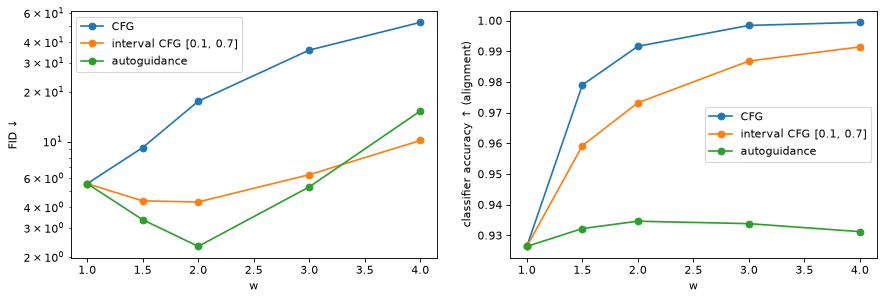

In [9]:
import json
RESULTS = 'ckpts/guidance_results.json'
RECOMPUTE = not os.path.exists(RESULTS)

ws = [1.0, 1.5, 2.0, 3.0, 4.0]
methods = {
    'CFG':                     dict(net=net),
    'interval CFG [0.1, 0.7]': dict(net=net, interval=(0.1, 0.7)),
    'autoguidance':            dict(net=net, bad_net=net_bad),
}
if RECOMPUTE:
    t0 = time.time()
    base = evaluate(net=net, w=1.0)                      # w = 1 is the same for all methods
    results = {name: [base] + [evaluate(w=w, **kw) for w in ws[1:]] for name, kw in methods.items()}
    print(f'{time.time() - t0:.0f}s')
    json.dump(results, open(RESULTS, 'w'))
results = json.load(open(RESULTS))
for name, r in results.items():
    print(f'{name:24s}', ' | '.join(f'w={w}: FID {f:5.2f}, acc {a:.3f}' for w, (f, a) in zip(ws, r)))

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for name, r in results.items():
    axs[0].plot(ws, [f for f, _ in r], 'o-', label=name)
    axs[1].plot(ws, [a for _, a in r], 'o-', label=name)
axs[0].set_xlabel('w'); axs[0].set_ylabel('FID ↓'); axs[0].legend(); axs[0].set_yscale('log')
axs[1].set_xlabel('w'); axs[1].set_ylabel('classifier accuracy ↑ (alignment)'); axs[1].legend()
plt.show()

### What to look at
* **CFG**: alignment → 100%, but FID gets worse with every step of $w$: the samples collapse to the most "typical" item of each class and FID penalises the lost diversity.
* **Interval CFG**: most of the alignment gain, and at $w=1.5$–$2$ FID is even *better* than without guidance.
* **Autoguidance**: the best FID, alignment almost unchanged. It does not use the unconditional model at all, it only pushes *away from the errors of the weaker model* — quality without the diversity loss.

FID and alignment disagree about the "best" $w$ — that is why papers report both, and why human evaluation is still needed.

One class, three methods, $w=3$, same seeds:

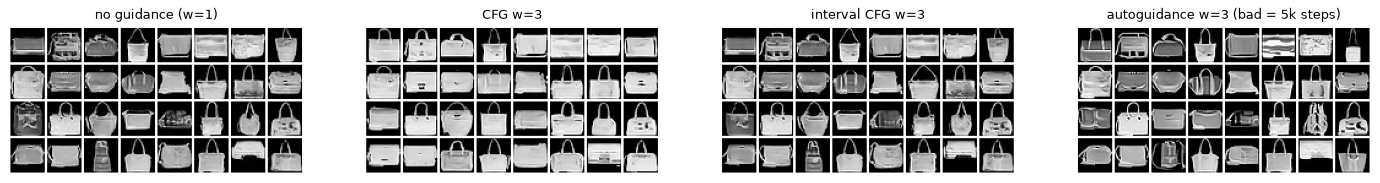

In [10]:
y_one = torch.full((32,), 8, device=dev)        # 'Bag'
fig, axs = plt.subplots(1, 4, figsize=(22, 6))
show(sample(net, y_one, w=1.0), nrow=8, ax=axs[0], title='no guidance (w=1)')
show(sample(net, y_one, w=3.0), nrow=8, ax=axs[1], title='CFG w=3')
show(sample(net, y_one, w=3.0, interval=(0.1, 0.7)), nrow=8, ax=axs[2], title='interval CFG w=3')
show(sample(net, y_one, w=3.0, bad_net=net_bad), nrow=8, ax=axs[3], title='autoguidance w=3 (bad = 5k steps)')
plt.show()

**Exercises**
1. Train with $x_0$-prediction instead of $v$-prediction (change the target and the sampler). Does anything change at 28×28? (Lecture: at 64×64 all three are similar.)
2. Autoguidance with the 1.5k-step `net_small` as the bad model. What goes wrong? (Too weak a bad model → artifacts; it should be only moderately worse.) Try a *smaller* DiT (depth 2) instead.
3. Plot FID vs number of Euler steps for $w=1$ and $w=3$. Which one needs more steps?